# From-scratch DPO: HH-RLHF and UltraFeedback

**Before running**
1. Push the updated repo (`batching.py`, `losses.py`, `preference_data.py`, `train_dpo.py`, adapter) to GitHub.
2. Notebook settings: **Accelerator = GPU T4 x2**, **Internet = On**.
3. **Add Input** → your saved SFT notebook version. The notebook finds `outputs/sft/best` inside it automatically.
4. Private repo: Kaggle secret `GITHUB_TOKEN`, as in the SFT notebook.

**Layouts**
- `"parallel"` (default): both tracks train **at the same time**, one per GPU (policy + reference on the same GPU). Takes about as long as one run.
- `"sequential"`: one track at a time, with the policy on `cuda:0` and the reference on `cuda:1` (the manual's layout). About twice as long. Use it if the pilot shows a GPU running out of memory in parallel.

**How to use**
- **Pilot:** `MODE = "pilot"`, run all cells interactively (~5 min). It checks both datasets load, step 0 loss is log 2, memory fits, and projects the full runtime.
- **Full:** `MODE = "full"`, then **Save Version → Save & Run All (Commit)**.

In [1]:
# ---- Configuration ----
MODE = "full"                    # "pilot" or "full"
LAYOUT = "parallel"               # "parallel" (one GPU per track) or "sequential"
TRACKS = ["hh", "ultrafeedback"]

REPO_URL = "https://github.com/HafsaKamran/small-model-alignment-starter.git"
BRANCH = "main"
REPO_DIR = "/kaggle/working/small-model-alignment"
SFT_CKPT = None                   # None = find .../outputs/sft/best under /kaggle/input automatically

MODE_ARGS = {
    "pilot": ["--n_train", "320", "--n_val", "64", "--eval_every", "5", "--log_every", "1"],
    # manual §10.4 recipe; everything else is a train_dpo.py default
    # (beta 0.1, fixed lr 1e-6, batch 1 x accum 32, RMSprop, clip 1.0, max prompt 256, context 512)
    "full":  ["--n_train", "15000", "--n_val", "1000", "--eval_every", "50", "--log_every", "10"],
}
EXTRA_ARGS = ["--eval_batch_size", "2"]                   # e.g. ["--ref_dtype", "float16"] or ["--gradient_checkpointing"] if memory is tight
FULL_STEPS = 15000 // 32          # optimizer steps in a full run, for the runtime projection

def run_name(track):
    return f"dpo_{track}" + ("_pilot" if MODE == "pilot" else "")

assert MODE in MODE_ARGS and LAYOUT in ("parallel", "sequential")
print(MODE, LAYOUT, TRACKS)

full parallel ['hh', 'ultrafeedback']


## 1. GPUs, repo, dependencies

In [2]:
!nvidia-smi
import torch
print("CUDA:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
assert torch.cuda.device_count() >= 2 or LAYOUT == "sequential", "parallel layout needs 2 GPUs (GPU T4 x2)" 

Mon Oct 12 10:11:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os, subprocess

url = REPO_URL
try:
    from kaggle_secrets import UserSecretsClient
    url = REPO_URL.replace("https://", f"https://{UserSecretsClient().get_secret('GITHUB_TOKEN')}@")
    print("Using GITHUB_TOKEN secret")
except Exception:
    print("No GITHUB_TOKEN secret; cloning as a public repo")

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, url, REPO_DIR], check=True)

%cd {REPO_DIR}
!git log -1 --oneline

Using GITHUB_TOKEN secret


Cloning into '/kaggle/working/small-model-alignment'...


/kaggle/working/small-model-alignment
42d0387 (grafted, HEAD -> main, origin/main, origin/HEAD) dpo implementation


In [4]:
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps || echo "editable install failed; fine, we run with python -m from the repo root"
import transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 85.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for small-model-alignment-starter (pyproject.toml) ..

## 2. All public tests (SFT + DPO) should pass

In [5]:
!PYTHONPATH=. python -m pytest -q tests/test_public_adapter_smoke.py

.......                                                                  [100%]
7 passed in 2.00s


## 3. Find the SFT checkpoint

In [6]:
import glob, os

if SFT_CKPT is None:
    found = sorted(os.path.dirname(p) for p in glob.glob("/kaggle/input/**/config.json", recursive=True)
                   if p.replace("\\", "/").endswith("/sft/best/config.json"))
    print("candidates:", found)
    assert found, "No .../sft/best found. Add your SFT notebook output via Add Input, or set SFT_CKPT"
    SFT_CKPT = found[0]
assert any(os.path.exists(os.path.join(SFT_CKPT, f)) for f in ("model.safetensors", "model.safetensors.index.json")), SFT_CKPT
print("SFT checkpoint:", SFT_CKPT)
!ls -la {SFT_CKPT}

candidates: ['/kaggle/input/notebooks/hafsakamran/01-sft-train/small-model-alignment/outputs/sft/best']
SFT checkpoint: /kaggle/input/notebooks/hafsakamran/01-sft-train/small-model-alignment/outputs/sft/best
total 1945380
drwxr-xr-x 2 nobody nogroup          0 Oct 12 10:08 .
drwxr-xr-x 4 nobody nogroup          0 Oct 12 10:08 ..
-rw-r--r-- 1 nobody nogroup        605 Oct 12 10:08 added_tokens.json
-rw-r--r-- 1 nobody nogroup       2427 Oct 12 10:08 chat_template.jinja
-rw-r--r-- 1 nobody nogroup       1249 Oct 12 10:08 config.json
-rw-r--r-- 1 nobody nogroup        117 Oct 12 10:08 generation_config.json
-rw-r--r-- 1 nobody nogroup    1671853 Oct 12 10:08 merges.txt
-rw-r--r-- 1 nobody nogroup 1976163472 Oct 12 10:10 model.safetensors
-rw-r--r-- 1 nobody nogroup        616 Oct 12 10:08 special_tokens_map.json
-rw-r--r-- 1 nobody nogroup       4689 Oct 12 10:08 tokenizer_config.json
-rw-r--r-- 1 nobody nogroup   11421896 Oct 12 10:08 tokenizer.json
-rw-r--r-- 1 nobody nogroup    2776833

## 4. Train

Each run streams to `outputs/<run>/train.log`, and this cell prints new lines as they arrive. If any run fails, the cell raises, so a background commit shows as failed.

In [7]:
import os, subprocess, sys, time

def command(track, policy_device, ref_device):
    return [sys.executable, "-m", "src.alignment.train_dpo", "--track", track,
            "--sft_checkpoint", SFT_CKPT, "--output_dir", f"{REPO_DIR}/outputs/{run_name(track)}",
            "--policy_device", policy_device, "--ref_device", ref_device, "--seed", "42",
            *MODE_ARGS[MODE], *EXTRA_ARGS]

if LAYOUT == "parallel":
    plan = [[(track, f"cuda:{i}", f"cuda:{i}") for i, track in enumerate(TRACKS)]]   # one wave, both at once
else:
    plan = [[(track, "cuda:0", "cuda:1")] for track in TRACKS]                        # one wave per track

env = dict(os.environ, PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True", TOKENIZERS_PARALLELISM="false")

for wave in plan:
    procs = {}
    for track, pdev, rdev in wave:
        out_dir = f"{REPO_DIR}/outputs/{run_name(track)}"
        os.makedirs(out_dir, exist_ok=True)
        log = open(f"{out_dir}/train.log", "w")
        cmd = command(track, pdev, rdev)
        print(f"[{track}]", " ".join(cmd), flush=True)
        procs[track] = (subprocess.Popen(cmd, cwd=REPO_DIR, env=env, stdout=log, stderr=subprocess.STDOUT), log, out_dir)

    printed = {track: 0 for track in procs}
    def show_new_lines():
        for track, (_, _, out_dir) in procs.items():
            lines = open(f"{out_dir}/train.log").read().splitlines()
            for line in lines[printed[track]:]:
                print(f"[{track}] {line}", flush=True)
            printed[track] = len(lines)

    while any(p.poll() is None for p, _, _ in procs.values()):
        time.sleep(20)
        show_new_lines()
    show_new_lines()

    failed = [t for t, (p, log, _) in procs.items() if p.returncode != 0]
    for _, log, _ in procs.values():
        log.close()
    if failed:
        raise RuntimeError(f"run(s) failed: {failed}; see the [track] lines above or outputs/<run>/train.log")
print("all runs finished")

[hh] /usr/bin/python3 -m src.alignment.train_dpo --track hh --sft_checkpoint /kaggle/input/notebooks/hafsakamran/01-sft-train/small-model-alignment/outputs/sft/best --output_dir /kaggle/working/small-model-alignment/outputs/dpo_hh --policy_device cuda:0 --ref_device cuda:0 --seed 42 --n_train 15000 --n_val 1000 --eval_every 50 --log_every 10 --eval_batch_size 2
[ultrafeedback] /usr/bin/python3 -m src.alignment.train_dpo --track ultrafeedback --sft_checkpoint /kaggle/input/notebooks/hafsakamran/01-sft-train/small-model-alignment/outputs/sft/best --output_dir /kaggle/working/small-model-alignment/outputs/dpo_ultrafeedback --policy_device cuda:1 --ref_device cuda:1 --seed 42 --n_train 15000 --n_val 1000 --eval_every 50 --log_every 10 --eval_batch_size 2
[hh] The tokenizer you are loading from '/kaggle/input/notebooks/hafsakamran/01-sft-train/small-model-alignment/outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discuss

## 5. Summary, checks and plots

===== hh =====
  step    0  val_loss 0.6931  reward_acc 0.000  margin +0.0000  (baseline)
  step   50  val_loss 0.6623  reward_acc 0.599  margin +0.1215  (best so far)
  step  100  val_loss 0.6516  reward_acc 0.615  margin +0.1729  (best so far)
  step  150  val_loss 0.6530  reward_acc 0.608  margin +0.1846
  step  200  val_loss 0.6464  reward_acc 0.627  margin +0.1998  (best so far)
  step  250  val_loss 0.6498  reward_acc 0.618  margin +0.2065
  step  300  val_loss 0.6473  reward_acc 0.613  margin +0.2177
  step  350  val_loss 0.6356  reward_acc 0.618  margin +0.2578
  step  400  val_loss 0.6281  reward_acc 0.646  margin +0.2704  (best so far)
  step  450  val_loss 0.6300  reward_acc 0.651  margin +0.2770  (best so far)
  step  469  val_loss 0.6263  reward_acc 0.651  margin +0.2944
  peak GPU mem 12.70 GB | fp16 skipped steps 3 | 105.0 min


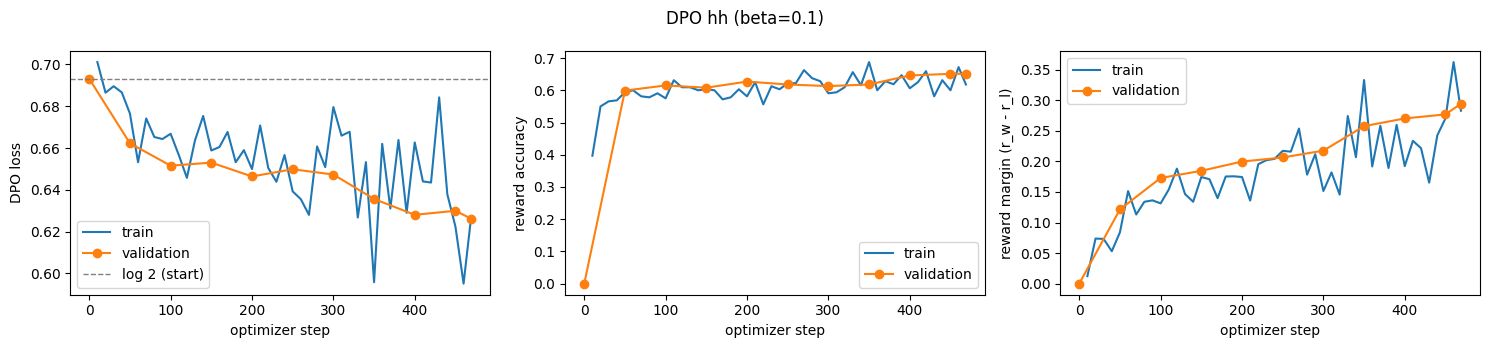

===== ultrafeedback =====
  step    0  val_loss 0.6931  reward_acc 0.000  margin +0.0000  (baseline)
  step   50  val_loss 0.5776  reward_acc 0.702  margin +0.5003  (best so far)
  step  100  val_loss 0.5637  reward_acc 0.710  margin +0.6293  (best so far)
  step  150  val_loss 0.5432  reward_acc 0.723  margin +0.7054  (best so far)
  step  200  val_loss 0.5343  reward_acc 0.728  margin +0.7365  (best so far)
  step  250  val_loss 0.5311  reward_acc 0.727  margin +0.7746
  step  300  val_loss 0.5283  reward_acc 0.730  margin +0.7487  (best so far)
  step  350  val_loss 0.5283  reward_acc 0.728  margin +0.7818
  step  400  val_loss 0.5215  reward_acc 0.740  margin +0.8131  (best so far)
  step  450  val_loss 0.5301  reward_acc 0.736  margin +0.8344
  step  469  val_loss 0.5260  reward_acc 0.731  margin +0.8244
  peak GPU mem 12.70 GB | fp16 skipped steps 3 | 140.59 min


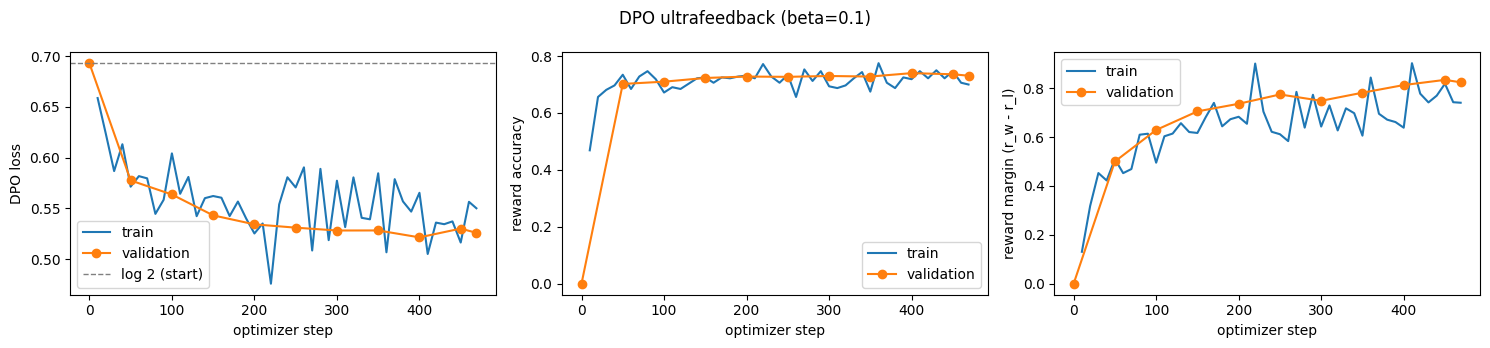

Checks passed


In [8]:
import json, math, os
import matplotlib.pyplot as plt

for track in TRACKS:
    out_dir = f"{REPO_DIR}/outputs/{run_name(track)}"
    records = [json.loads(l) for l in open(f"{out_dir}/metrics.jsonl")]
    train = [r for r in records if r["type"] == "train"]
    evals = [r for r in records if r["type"] == "eval"]
    summary = json.load(open(f"{out_dir}/summary.json"))

    print(f"===== {track} =====")
    for r in evals:
        tag = "  (baseline)" if r.get("baseline") else ("  (best so far)" if r.get("best_so_far") else "")
        print(f"  step {r['step']:>4}  val_loss {r['val_loss']:.4f}  reward_acc {r['val_reward_acc']:.3f}  "
              f"margin {r['val_reward_margin']:+.4f}{tag}")
    peak = max(r.get("max_mem_gb", 0) for r in train)
    print(f"  peak GPU mem {peak:.2f} GB | fp16 skipped steps {summary['skipped_steps']} | {summary['minutes']} min")
    if MODE == "pilot":
        per_step = train[-1]["elapsed_min"] / train[-1]["step"]
        print(f"  projected full run: ~{per_step * FULL_STEPS / 60:.1f} h "
              f"(rough: pilot evals are smaller, full evals of 1000 pairs add time)")

    # Checks
    assert all(math.isfinite(r["train_loss"]) for r in train), f"{track}: NaN/inf loss"
    assert abs(evals[0]["val_loss"] - math.log(2)) < 1e-3, f"{track}: step-0 loss should be log 2 (policy == reference)"
    assert os.path.isdir(f"{out_dir}/best") and os.path.isdir(f"{out_dir}/final"), f"{track}: missing checkpoint"
    if MODE == "full":
        assert summary["best_val_reward_acc"] > 0.5, f"{track}: reward accuracy never beat chance"

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    steps_t, steps_e = [r["step"] for r in train], [r["step"] for r in evals]
    axes[0].plot(steps_t, [r["train_loss"] for r in train], label="train")
    axes[0].plot(steps_e, [r["val_loss"] for r in evals], "o-", label="validation")
    axes[0].axhline(math.log(2), ls="--", c="gray", lw=1, label="log 2 (start)")
    axes[0].set_ylabel("DPO loss")
    axes[1].plot(steps_t, [r["train_reward_acc"] for r in train], label="train")
    axes[1].plot(steps_e, [r["val_reward_acc"] for r in evals], "o-", label="validation")
    axes[1].set_ylabel("reward accuracy")
    axes[2].plot(steps_t, [r["train_reward_margin"] for r in train], label="train")
    axes[2].plot(steps_e, [r["val_reward_margin"] for r in evals], "o-", label="validation")
    axes[2].set_ylabel("reward margin (r_w - r_l)")
    for ax in axes:
        ax.set_xlabel("optimizer step"); ax.legend()
    fig.suptitle(f"DPO {track} (beta=0.1)")
    fig.tight_layout()
    fig.savefig(f"{out_dir}/dpo_curves.png", dpi=150)
    plt.show()
print("Checks passed")

## 6. Package small outputs (full run only)

Only the logs, configs, splits and plots go in the zip. The checkpoints stay in `outputs/` and are kept by the saved version. Copying 4 × 2 GB checkpoints into a zip would nearly fill Kaggle's 20 GB working disk.

In [9]:
import glob, os, zipfile

if MODE == "full":
    zip_path = "/kaggle/working/dpo_run_outputs.zip"
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for track in TRACKS:
            out_dir = f"{REPO_DIR}/outputs/{run_name(track)}"
            for path in glob.glob(f"{out_dir}/*"):
                if os.path.isfile(path):
                    zf.write(path, os.path.relpath(path, f"{REPO_DIR}/outputs"))
    print("wrote", zip_path, f"{os.path.getsize(zip_path)/1e6:.1f} MB")
else:
    print("Pilot: skipping zip")
!du -sh {REPO_DIR}/outputs/* 2>/dev/null
!df -h /kaggle/working | tail -1

wrote /kaggle/working/dpo_run_outputs.zip 2.3 MB
3.8G	/kaggle/working/small-model-alignment/outputs/dpo_hh
3.8G	/kaggle/working/small-model-alignment/outputs/dpo_ultrafeedback
/dev/loop2       20G  7.5G   13G  39% /kaggle/working
